In [1]:

import pandas as pd

data = {
    "Order_ID": [101, 102, 103, 104, 105, 106,
                 107, 108, 109, 110, 111, 102],

    "Date": ["2026-10-01", "2026-10-01", "2026-10-02",
             "2026-10-02", "2026-10-03", "2026-10-03",
             "2026-10-04", "2026-10-04", "2026-10-05",
             "2026-10-05", "2026-10-06", "2026-10-01"],

    "Product": ["Notebook", "Pen", "Water Bottle", "Backpack",
                "Notebook", "Pen", "Lunch Box", "Backpack",
                "Notebook", "Pen", "Water Bottle", "Pen"],

    "Category": ["Stationery", "Stationery", "Accessories",
                 "Accessories", "Stationery", "Stationery",
                 "Accessories", "Accessories", "Stationery",
                 "Stationery", "Accessories", "Stationery"],

    "Quantity": [10, 20, 5, 3, 8, 25, 4, 2, None, 15, 7, 20],

    "Unit_Price": [50, 10, 120, 650, 50, 10,
                   180, 650, 50, 10, 120, 10]
}

df = pd.DataFrame(data)

df.to_csv("shop_sales.csv", index=False)

print("CSV file successfully created!")
print("Total rows:", len(df))


CSV file successfully created!
Total rows: 12


In [2]:

df = pd.read_csv("shop_sales.csv")

print("First 5 rows:")
display(df.head())

print("Dataset shape:")
print(df.shape)

print("Column names:")
print(df.columns.tolist())

print("Data information:")
df.info()


First 5 rows:


,Order_ID,Date,Product,Category,Quantity,Unit_Price
0,101,2026-10-01,Notebook,Stationery,10.0,50
1,102,2026-10-01,Pen,Stationery,20.0,10
2,103,2026-10-02,Water Bottle,Accessories,5.0,120
3,104,2026-10-02,Backpack,Accessories,3.0,650
4,105,2026-10-03,Notebook,Stationery,8.0,50


Dataset shape:
(12, 6)
Column names:
['Order_ID', 'Date', 'Product', 'Category', 'Quantity', 'Unit_Price']
Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order_ID    12 non-null     int64  
 1   Date        12 non-null     object 
 2   Product     12 non-null     object 
 3   Category    12 non-null     object 
 4   Quantity    11 non-null     float64
 5   Unit_Price  12 non-null     int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 708.0+ bytes


In [3]:

# 1. Missing values check karo
print("Missing values:")
print(df.isnull().sum())

# 2. Duplicate rows check karo
print("\nDuplicate rows:")
print(df.duplicated().sum())

# 3. Duplicate records display karo
display(df[df.duplicated()])


Missing values:
Order_ID      0
Date          0
Product       0
Category      0
Quantity      1
Unit_Price    0
dtype: int64

Duplicate rows:
1


,Order_ID,Date,Product,Category,Quantity,Unit_Price
11,102,2026-10-01,Pen,Stationery,20.0,10


In [4]:

# Original data ki copy banao
df_clean = df.copy()

# Duplicate rows hatao
df_clean = df_clean.drop_duplicates()

# Missing Quantity ko median se fill karo
median_quantity = df_clean["Quantity"].median()

df_clean["Quantity"] = df_clean["Quantity"].fillna(
    median_quantity
)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nRows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))

display(df_clean)


Missing values after cleaning:
Order_ID      0
Date          0
Product       0
Category      0
Quantity      0
Unit_Price    0
dtype: int64

Rows before cleaning: 12
Rows after cleaning: 11


,Order_ID,Date,Product,Category,Quantity,Unit_Price
0,101,2026-10-01,Notebook,Stationery,10.0,50
1,102,2026-10-01,Pen,Stationery,20.0,10
2,103,2026-10-02,Water Bottle,Accessories,5.0,120
3,104,2026-10-02,Backpack,Accessories,3.0,650
4,105,2026-10-03,Notebook,Stationery,8.0,50
5,106,2026-10-03,Pen,Stationery,25.0,10
6,107,2026-10-04,Lunch Box,Accessories,4.0,180
7,108,2026-10-04,Backpack,Accessories,2.0,650
8,109,2026-10-05,Notebook,Stationery,7.5,50
9,110,2026-10-05,Pen,Stationery,15.0,10


In [5]:

# Step 1: Har product ki sales calculate karo
df_clean["Total_Sales"] = (
    df_clean["Quantity"] * df_clean["Unit_Price"]
)

# Step 2: Total shop sales calculate karo
total_sales = df_clean["Total_Sales"].sum()

print("Total Shop Sales:", total_sales)

# Step 3: Product-wise revenue calculate karo
product_sales = (
    df_clean.groupby("Product")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("\nProduct-wise Revenue:")
display(product_sales)


Total Shop Sales: 7285.0

Product-wise Revenue:


Product
Backpack        3250.0
Water Bottle    1440.0
Notebook        1275.0
Lunch Box        720.0
Pen              600.0
Name: Total_Sales, dtype: float64

In [6]:

# Product-wise quantity sold
product_quantity = (
    df_clean.groupby("Product")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("Product-wise Quantity Sold:")
display(product_quantity)

print("\nHighest Revenue Product:")
print(product_sales.idxmax())

print("\nHighest Quantity Product:")
print(product_quantity.idxmax())


Product-wise Quantity Sold:


Product
Pen             60.0
Notebook        25.5
Water Bottle    12.0
Backpack         5.0
Lunch Box        4.0
Name: Quantity, dtype: float64


Highest Revenue Product:
Backpack

Highest Quantity Product:
Pen


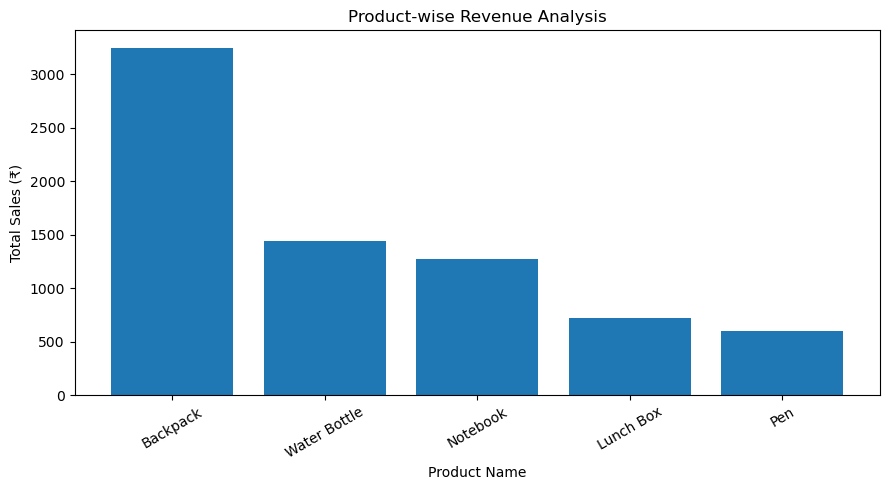

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(product_sales.index, product_sales.values)

plt.title("Product-wise Revenue Analysis")
plt.xlabel("Product Name")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

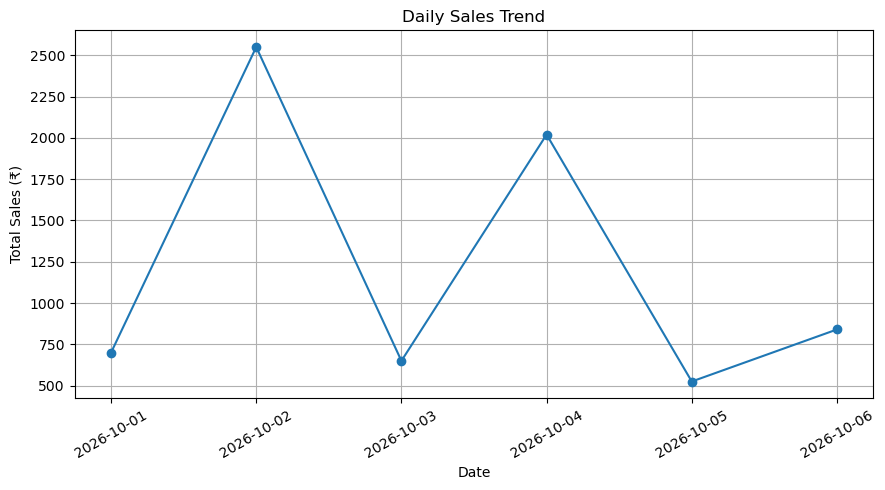

Date
2026-10-01     700.0
2026-10-02    2550.0
2026-10-03     650.0
2026-10-04    2020.0
2026-10-05     525.0
2026-10-06     840.0
Name: Total_Sales, dtype: float64

In [8]:
# Date column ko date format mein convert karna
df_clean["Date"] = pd.to_datetime(df_clean["Date"])

# Date-wise total sales calculate karna
daily_sales = (
    df_clean.groupby("Date")["Total_Sales"]
    .sum()
    .sort_index()
)

# Line chart banana
plt.figure(figsize=(9, 5))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    marker="o"
)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=30)
plt.grid(True)

plt.tight_layout()
plt.show()

# Date-wise sales dekhna
display(daily_sales)

In [9]:
# Insight 1: Sabse zyada revenue kis product se aaya?
best_revenue_product = product_sales.idxmax()
best_revenue = product_sales.max()

# Insight 2: Sabse zyada quantity kis product ki biki?
best_quantity_product = product_quantity.idxmax()
best_quantity = product_quantity.max()

# Insight 3: Sabse zyada sales kis din hui?
best_sales_date = daily_sales.idxmax()
best_daily_sales = daily_sales.max()

print("BUSINESS INSIGHTS")
print("-" * 40)

print(
    f"1. Highest Revenue Product: {best_revenue_product} "
    f"(₹{best_revenue:.2f})"
)

print(
    f"2. Highest Quantity Sold: {best_quantity_product} "
    f"({best_quantity} units)"
)

print(
    f"3. Best Sales Day: {best_sales_date.strftime('%Y-%m-%d')} "
    f"(₹{best_daily_sales:.2f})"
)

BUSINESS INSIGHTS
----------------------------------------
1. Highest Revenue Product: Backpack (₹3250.00)
2. Highest Quantity Sold: Pen (60.0 units)
3. Best Sales Day: 2026-10-02 (₹2550.00)


In [10]:
print("=" * 45)
print("       SHOP SALES ANALYSIS REPORT")
print("=" * 45)

print(f"Total Orders/Rows Analyzed: {len(df_clean)}")
print(f"Total Revenue: ₹{total_sales:.2f}")
print(f"Products Analyzed: {df_clean['Product'].nunique()}")

print("\nTOP PERFORMING PRODUCTS")
print("-" * 45)
display(product_sales)

print("\nDAILY SALES SUMMARY")
print("-" * 45)
display(daily_sales)

print("\nKEY BUSINESS INSIGHTS")
print("-" * 45)
print(f"Highest Revenue Product: {best_revenue_product}")
print(f"Highest Quantity Product: {best_quantity_product}")
print(f"Best Sales Day: {best_sales_date.strftime('%Y-%m-%d')}")

print("\nReport generated successfully!")

       SHOP SALES ANALYSIS REPORT
Total Orders/Rows Analyzed: 11
Total Revenue: ₹7285.00
Products Analyzed: 5

TOP PERFORMING PRODUCTS
---------------------------------------------


Product
Backpack        3250.0
Water Bottle    1440.0
Notebook        1275.0
Lunch Box        720.0
Pen              600.0
Name: Total_Sales, dtype: float64


DAILY SALES SUMMARY
---------------------------------------------


Date
2026-10-01     700.0
2026-10-02    2550.0
2026-10-03     650.0
2026-10-04    2020.0
2026-10-05     525.0
2026-10-06     840.0
Name: Total_Sales, dtype: float64


KEY BUSINESS INSIGHTS
---------------------------------------------
Highest Revenue Product: Backpack
Highest Quantity Product: Pen
Best Sales Day: 2026-10-02

Report generated successfully!
